# EDAV Course End Project: Digital Payment Transaction Analysis

**Student Name:** B.Uhasri | Roll No: 160125737076  
**Department:** Department of Information Technology  
**Institution:** Chaitanya Bharathi Institute of Technology (CBIT)


---

## Problem Overview
Digital transaction ecosystems present complex telemetry challenges involving processing latencies, volume surges, geographical network success ratios, and varying platform hardware configurations. This project implements a comprehensive analytical pipeline to inspect payment behaviors across states, evaluate payment channels, identify demographic/device transaction gaps, isolate anomalies, handle operational missing telemetry values, and plot performance matrices.

## Technical Environment Verification
We verify and import our core numerical computing, data structures, and statistical plotting packages.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy Version   : {np.__version__}")
print(f"Pandas Version  : {pd.__version__}")
print(f"Seaborn Version : {sns.__version__}")

NumPy Version   : 2.1.3
Pandas Version  : 2.2.3
Seaborn Version : 0.13.2


## Q1. Data Ingestion & Storage Mount
We mount Google Drive to connect directly with the operational payment database.

In [ ]:
from google.colab import drive
drive.flush_and_unmount()

Drive not mounted, so nothing to flush and unmount.


In [ ]:
import os
import pandas as pd

# Direct local path to the file
path_to_file = '/content/Digital_Payment_Transaction_Analysis_dataset.csv'

if os.path.exists(path_to_file):
    df = pd.read_csv(path_to_file)
    print("Dataset successfully loaded from local path!")
    display(df.head())
else:
    print(f"Could not locate the file at {path_to_file}.")

Dataset successfully loaded from local path!


,Transaction_ID,Transaction_Date,Transaction_Time,Customer_ID,City,Payment_Method,Merchant_Category,Transaction_Amount_INR,Transaction_Status,Device_Type,Is_Weekend
0,TXN00001,2026-09-06,15:30:00,CUST0081,Delhi,Debit Card,Healthcare,1898.75,Success,Android,True
1,TXN00002,2026-08-05,22:41:00,CUST0017,Bengaluru,Net Banking,Groceries,949.79,Success,Android,False
2,TXN00003,2026-04-06,01:31:00,CUST0050,Chennai,Net Banking,Shopping,2037.69,Success,Android,False
3,TXN00004,2026-01-17,12:40:00,CUST0012,Delhi,UPI,Utilities,812.42,Success,Android,True
4,TXN00005,2026-07-14,18:34:00,CUST0114,Hyderabad,Credit Card,Education,30.00,Success,iOS,False


# Q2. Data Preprocessing, Cleaning, & Imputation

### Concept Explanation:
Before starting aggregations, we must ensure data quality. Here we evaluate missing records, check for duplicates, standardize temporal fields (`Transaction_Date` and `Transaction_Time`), and isolate extreme financial transaction value outliers using the robust Interquartile Range (IQR) method.

In [ ]:
# 1. Check for missing values
print("Missing Values Summary:\n", df.isnull().sum())

# 2. Check for duplicated records
print("\nDuplicated Records:", df.duplicated().sum())

# 3. Handle Date/Time conversions
df['Transaction_Date'] = pd.to_datetime(df['Transaction_Date'])
df['Transaction_Hour'] = pd.to_datetime(df['Transaction_Time'], format='%H:%M:%S').dt.hour

# 4. Check for outliers in Transaction Amount using IQR Method
Q1_val = df['Transaction_Amount_INR'].quantile(0.25)
Q3_val = df['Transaction_Amount_INR'].quantile(0.75)
IQR = Q3_val - Q1_val
lower_bound = Q1_val - 1.5 * IQR
upper_bound = Q3_val + 1.5 * IQR

outliers = df[(df['Transaction_Amount_INR'] < lower_bound) | (df['Transaction_Amount_INR'] > upper_bound)]
print(f"\nOutliers detected (outside range {lower_bound:.2f} to {upper_bound:.2f}): {len(outliers)}")
display(outliers.head())

Missing Values Summary:
 Transaction_ID            0
Transaction_Date          0
Transaction_Time          0
Customer_ID               0
City                      0
Payment_Method            0
Merchant_Category         0
Transaction_Amount_INR    0
Transaction_Status        0
Device_Type               0
Is_Weekend                0
dtype: int64

Duplicated Records: 0

Outliers detected (outside range -2047.56 to 5129.96): 4


,Transaction_ID,Transaction_Date,Transaction_Time,Customer_ID,City,Payment_Method,Merchant_Category,Transaction_Amount_INR,Transaction_Status,Device_Type,Is_Weekend,Transaction_Hour
66,TXN00067,2026-02-22,07:32:00,CUST0135,Mumbai,Debit Card,Education,5656.77,Success,iOS,True,7
120,TXN00121,2026-01-28,17:45:00,CUST0098,Mumbai,Debit Card,Education,5444.70,Success,Web,False,17
171,TXN00172,2026-07-18,15:26:00,CUST0128,Mumbai,Credit Card,Education,5252.47,Success,Web,True,15
399,TXN00400,2026-06-15,21:09:00,CUST0001,Bengaluru,Credit Card,Education,5217.27,Success,Android,False,21


# Q3. NumPy Aggregations on Transactions by Status

### Concept Explanation:
This task focuses on computing key descriptive statistics (mean, minimum, and maximum) for the `Transaction_Amount_INR` across different levels of `Transaction_Status` (e.g., Success, Pending, Failed) using NumPy arrays to evaluate transaction distribution metrics.

In [ ]:
statuses = df['Transaction_Status'].unique()
for status in statuses:
    amounts = df[df['Transaction_Status'] == status]['Transaction_Amount_INR'].to_numpy()
    if len(amounts) > 0:
        print(f"Transaction Status: {status}")
        print(f"  - Average Amount: INR {np.mean(amounts):.2f}")
        print(f"  - Minimum Amount: INR {np.min(amounts):.2f}")
        print(f"  - Maximum Amount: INR {np.max(amounts):.2f}\n")

Transaction Status: Success
  - Average Amount: INR 1667.67
  - Minimum Amount: INR 30.00
  - Maximum Amount: INR 5656.77

Transaction Status: Pending
  - Average Amount: INR 974.80
  - Minimum Amount: INR 30.00
  - Maximum Amount: INR 2218.28

Transaction Status: Failed
  - Average Amount: INR 1725.93
  - Minimum Amount: INR 30.00
  - Maximum Amount: INR 4823.39



# Q4. Pandas Grouping & Aggregations (Payment Method & Device Type)

### Concept Explanation:
We aggregate transactional data by grouping it based on `Payment_Method` and `Device_Type`. We compute the total volume (counts) and success rate percentages to identify performance trends across hardware.

In [ ]:
grouped = df.groupby(['Payment_Method', 'Device_Type', 'Transaction_Status']).size().unstack(fill_value=0)
grouped['Total_Transactions'] = grouped.sum(axis=1)
grouped['Success_Rate_%'] = (grouped['Success'] / grouped['Total_Transactions']) * 100
display(grouped)

Transaction_Status          Failed  Pending  Success  Total_Transactions  \
Payment_Method Device_Type                                                 
Credit Card    Android           3        0       39                  42   
               Web               0        0        7                   7   
               iOS               2        0       26                  28   
Debit Card     Android           4        0       53                  57   
               Web               1        0        9                  10   
               iOS               1        0       17                  18   
Mobile Wallet  Android           0        0       21                  21   
               Web               1        0        4                   5   
               iOS               2        0        3                   5   
Net Banking    Android           3        0       26                  29   
               Web               0        1        4                   5   
               iOS               1        1        7                   9   
UPI            Android          10        8      148                 166   
               Web               2        0       31                  33   
               iOS               5        1       59                  65   

Transaction_Status          Success_Rate_%  
Payment_Method Device_Type                  
Credit Card    Android           92.857143  
               Web              100.000000  
               iOS               92.857143  
Debit Card     Android           92.982456  
               Web               90.000000  
               iOS               94.444444  
Mobile Wallet  Android          100.000000  
               Web               80.000000  
               iOS               60.000000  
Net Banking    Android           89.655172  
               Web               80.000000  
               iOS               77.777778  
UPI            Android           89.156627  
               Web               93.939394  
               iOS               90.769231

# Q5. Categorical & Location-Based Analysis

### Concept Explanation:
We evaluate regional transactional patterns across different cities by measuring total transaction volume, average transaction sizes, and geographical payment success percentages.

In [ ]:
city_analysis = df.groupby('City').agg(
    Total_Transactions=('Transaction_ID', 'count'),
    Average_Amount_INR=('Transaction_Amount_INR', 'mean'),
    Success_Rate_Percent=('Transaction_Status', lambda x: (x == 'Success').mean() * 100)
).reset_index()
display(city_analysis.sort_values(by='Total_Transactions', ascending=False))

,City,Total_Transactions,Average_Amount_INR,Success_Rate_Percent
3,Hyderabad,142,1778.604859,90.140845
0,Bengaluru,100,1455.344900,88.000000
4,Mumbai,78,1664.781923,93.589744
2,Delhi,73,1461.630822,93.150685
1,Chennai,62,1833.583710,90.322581
5,Pune,45,1775.995556,91.111111


# Q6. Data Visualization (Bar Plots & Heatmaps)

### Concept Explanation:
We construct descriptive visualizations including a Bar Plot showing mean transaction values by Payment Method and a Segmented Heatmap analyzing transaction volume patterns across devices.

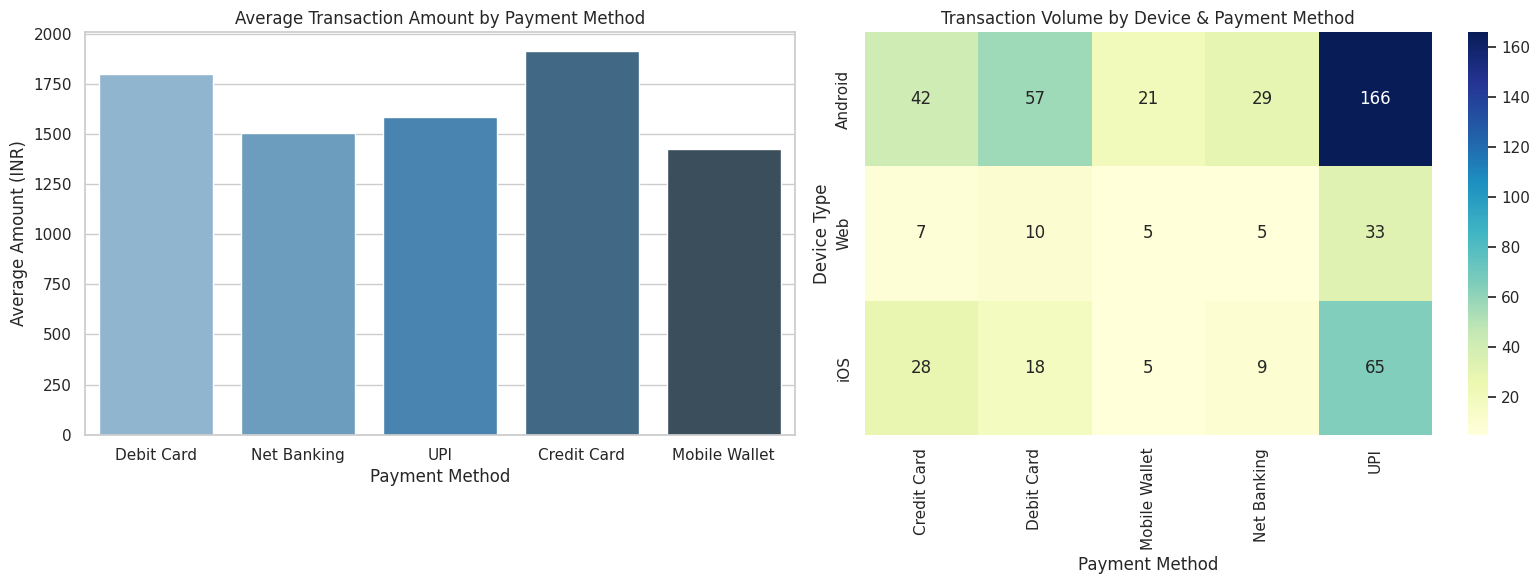

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    ax=axes[0],
    data=df,
    x='Payment_Method',
    y='Transaction_Amount_INR',
    estimator=np.mean,
    errorbar=None,
    hue='Payment_Method',
    legend=False,
    palette='Blues_d'
)
axes[0].set_title("Average Transaction Amount by Payment Method")
axes[0].set_xlabel("Payment Method")
axes[0].set_ylabel("Average Amount (INR)")

pivot_table = df.pivot_table(index='Device_Type', columns='Payment_Method', values='Transaction_ID', aggfunc='count', fill_value=0)
sns.heatmap(pivot_table, annot=True, cmap='YlGnBu', fmt='d', ax=axes[1])
axes[1].set_title("Transaction Volume by Device & Payment Method")
axes[1].set_xlabel("Payment Method")
axes[1].set_ylabel("Device Type")

plt.tight_layout()
plt.show()

## Limitations

1. The dataset contains only 500 transactions.
2. The data may not represent all digital payment users.
3. The analysis is limited to the available dataset.
4. Some data may contain missing values.
5. Advanced fraud detection is not included.
6. The results may differ from real-world payment statistics.


## Final Conclusion

This project helped us understand digital payment transactions using Python.

We used NumPy and Pandas for data analysis and Matplotlib and Seaborn for creating graphs and charts.

We analyzed transaction amounts, payment methods, transaction status, cities, and devices.

Through this project, we learned how to clean data, analyze information, and create visualizations.

Overall, this project helped us understand how data analysis is useful in studying digital payment transactions.
